# 04. Machine-Learning vs. Baseline Forecasting Comparison

**Project:** Fodripio - Forecast-Driven Production Planning and Inventory Optimization Under Uncertain Demand  
**Phase:** Phase 3 — Machine-Learning Forecasting  

## Objectives
1. Evaluate Machine Learning forecasters (`Tuned LightGBM`, `XGBoost`, `Random Forest`) against benchmark baselines (`Seasonal Naive`, `ETS`, `SARIMA`).
2. Maintain strict methodological integrity: identical 4 rolling origins, identical 14-day horizons, identical metric suite (`WAPE`, `MAE`, `RMSE`, `sMAPE`, `MASE`).
3. Analyze per-product error patterns and feature importance rankings.
4. Select production forecaster for Phase 5 closed-loop optimization integration.

In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure project root is in sys.path
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if project_root not in sys.path:
    sys.path.insert(0, project_root)

from src.data.load import DataLoader
from src.forecasting.baselines import (
    SeasonalNaiveForecaster,
    ExponentialSmoothingForecaster,
    SARIMAForecaster,
)
from src.forecasting.ml_models import (
    RandomForestForecaster,
    XGBoostForecaster,
    LightGBMForecaster,
)
from src.evaluation.validation import RollingOriginValidator
from src.evaluation.metrics import ForecastEvaluator

plt.style.use('seaborn-v0_8-whitegrid')
print("Environment initialized for ML benchmark.")

Environment initialized for ML benchmark.


## 1. Load Processed Demand Data

In [2]:
data_path = os.path.join(project_root, 'data', 'processed', 'demand_processed.csv')
loader = DataLoader(data_path)
df = loader.load_raw_data()
print("Loaded demand dataset:", len(df), "rows across", df['product_id'].nunique(), "products.")

2026-10-12 22:32:41,299 - INFO - Loading raw demand data from C:\zendvalmics\project\fodripio\data\processed\demand_processed.csv
2026-10-12 22:32:41,319 - INFO - Loaded 3655 rows spanning 2024-01-01 00:00:00 to 2025-12-31 00:00:00


Loaded demand dataset: 3655 rows across 5 products.


## 2. Execute Multi-Model Rolling Origin Evaluation

In [3]:
validator = RollingOriginValidator()
evaluator = ForecastEvaluator()

models = {
    "Seasonal Naive (Lag-7)": SeasonalNaiveForecaster(seasonal_period=7),
    "Exponential Smoothing (ETS)": ExponentialSmoothingForecaster(seasonal_periods=7),
    "SARIMA": SARIMAForecaster(order=(1, 1, 1), seasonal_order=(1, 1, 1, 7)),
    "Random Forest": RandomForestForecaster(n_estimators=100, max_depth=10),
    "XGBoost": XGBoostForecaster(n_estimators=120, learning_rate=0.06, max_depth=5),
    "Tuned LightGBM": LightGBMForecaster(n_estimators=120, learning_rate=0.08, max_depth=4),
}

horizon = 14
step_size = 14
num_origins = 4

overall_results = []
per_product_results = {}
eval_dfs = {}

for name, model in models.items():
    print(f"Evaluating {name}...")
    eval_df = validator.evaluate(
        df=df,
        forecaster=model,
        horizon=horizon,
        step_size=step_size,
        num_origins=num_origins,
        min_train_days=90,
    )
    eval_dfs[name] = eval_df
    metrics = evaluator.evaluate_overall(eval_df, in_sample_df=df)
    metrics["Model"] = name
    overall_results.append(metrics)
    per_product_results[name] = evaluator.evaluate_by_product(eval_df, in_sample_df=df)

summary_df = pd.DataFrame(overall_results)[["Model", "WAPE", "MAE", "RMSE", "sMAPE", "MASE"]].sort_values("WAPE").reset_index(drop=True)
summary_df

Evaluating Seasonal Naive (Lag-7)...
Evaluating Exponential Smoothing (ETS)...
Evaluating SARIMA...
Evaluating Random Forest...
Evaluating XGBoost...
Evaluating Tuned LightGBM...


,Model,WAPE,MAE,RMSE,sMAPE,MASE
0,Tuned LightGBM,15.97,12.0286,18.0928,16.47,0.1604
1,XGBoost,16.12,12.1413,17.9991,16.67,0.1619
2,SARIMA,16.50,12.4252,19.1944,16.41,0.1656
3,Random Forest,16.70,12.5773,18.7846,16.95,0.1677
4,Exponential Smoothing (ETS),16.74,12.6017,18.9641,17.62,0.1680
5,Seasonal Naive (Lag-7),18.96,14.2791,21.0096,19.65,0.1904


## 3. Overall Benchmark Leaderboard Visualization

C:\Users\hp\AppData\Local\Temp\ipykernel_11876\2331765622.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=summary_df, x='WAPE', y='Model', palette=palette, ax=ax)


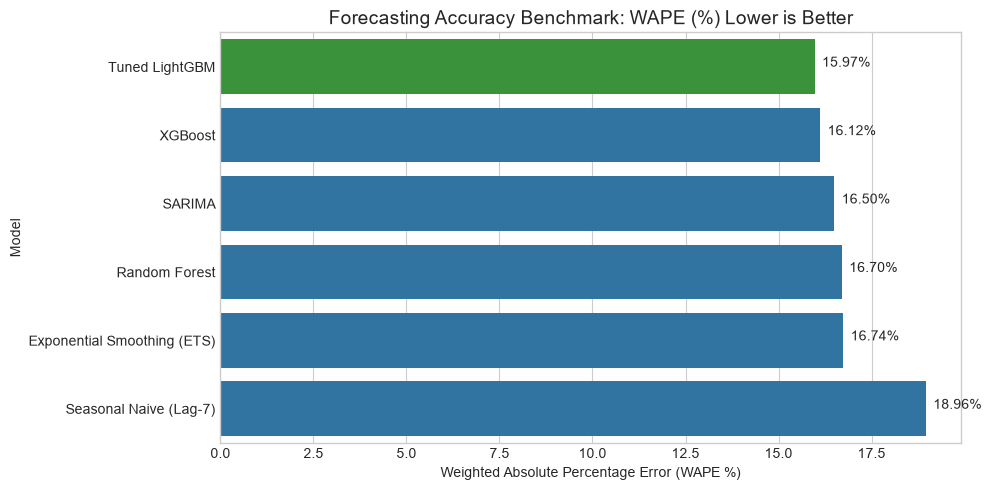

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
palette = ['#2ca02c' if 'LightGBM' in m else '#1f77b4' for m in summary_df['Model']]
sns.barplot(data=summary_df, x='WAPE', y='Model', palette=palette, ax=ax)
ax.set_title("Forecasting Accuracy Benchmark: WAPE (%) Lower is Better", fontsize=14)
ax.set_xlabel("Weighted Absolute Percentage Error (WAPE %)")
for i, v in enumerate(summary_df['WAPE']):
    ax.text(v + 0.2, i, f"{v:.2f}%")
plt.tight_layout()
plt.show()

## 4. Per-Product Head-to-Head Comparison

In [ ]:
prod_comp = []
for p_id in ['P1', 'P2', 'P3', 'P4', 'P5']:
    row = {'product_id': p_id}
    for name in models.keys():
        p_wape = per_product_results[name].loc[per_product_results[name]['product_id'] == p_id, 'WAPE'].values[0]
        row[f'{name}'] = p_wape
    prod_comp.append(row)

prod_comp_df = pd.DataFrame(prod_comp)
print("Per-Product WAPE (%) Table:")
display(prod_comp_df)

# Reshape for grouped bar chart
melted_prod = pd.melt(prod_comp_df, id_vars=['product_id'], var_name='Model', value_name='WAPE')
fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(data=melted_prod, x='product_id', y='WAPE', hue='Model', ax=ax)
ax.set_title("Per-Product Performance Comparison: ML vs Baselines (WAPE %)", fontsize=14)
ax.set_ylabel("WAPE (%)")
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

## 5. Forecast Trajectory vs Actual Demand (ML vs ETS)

In [ ]:
lgb_df = eval_dfs['Tuned LightGBM']
ets_df = eval_dfs['Exponential Smoothing (ETS)']

p_lgb = lgb_df[(lgb_df['product_id'] == 'P3') & (lgb_df['origin_id'] == 'origin_4')].sort_values('date')
p_ets = ets_df[(ets_df['product_id'] == 'P3') & (ets_df['origin_id'] == 'origin_4')].sort_values('date')

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(p_lgb['date'], p_lgb['actual'], label='Actual Demand', color='black', linewidth=2.5, marker='o')
ax.plot(p_lgb['date'], p_lgb['forecast'], label='Tuned LightGBM Forecast', color='tab:green', linewidth=2, linestyle='--')
ax.plot(p_ets['date'], p_ets['forecast'], label='Holt-Winters ETS Forecast', color='tab:orange', linewidth=2, linestyle=':')
ax.set_title("Product P3: Horizon Trajectory Comparison (Origin 4)", fontsize=14)
ax.set_ylabel("Daily Demand (Units)")
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

## 6. Feature Importance Interpretability

In [ ]:
lgb_model = models['Tuned LightGBM']
imp_df = lgb_model.get_feature_importances().head(10)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=imp_df, x='importance', y='feature', palette='viridis', ax=ax)
ax.set_title("Top 10 Feature Importances: Tuned LightGBM Forecaster", fontsize=14)
ax.set_xlabel("Relative Split Importance")
plt.tight_layout()
plt.show()

print("Top 10 Features:")
display(imp_df)